<a href="https://colab.research.google.com/github/NeuroNex-ModelX/drainage-failure-sri-lanka/blob/main/00_setup_boundaries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · Setup and DS-division boundaries
**Owner:** Jithmi · **Makes:** `data/processed/ds_divisions.gpkg`, `ds_list.csv`, `ds_divisions_simplified.geojson`

The DS-division list made here is the "spine" every other notebook joins to (by `pcode`).

**Before running:**
1. Go to https://data.humdata.org/dataset/cod-ab-lka and download the **shapefile zip** (SHP).
2. Upload the zip into the Drive folder `ModelX/data/raw/boundaries/` (no need to unzip).

In [4]:
# --- SETUP: run this cell first in every session ---
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ['MODELX_BASE'] = '/content/drive/MyDrive/ModelX'
sys.path.append(os.path.join(os.environ.get('MODELX_BASE', '..'), 'src'))
from common import *
print('Project folder:', BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/ModelX


In [12]:
import zipfile, glob
import geopandas as gpd

bdir = os.path.join(RAW, 'boundaries')
os.makedirs(bdir, exist_ok=True)
for z in glob.glob(os.path.join(bdir, '*.zip')):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(bdir)
    print('Unzipped', os.path.basename(z))

shps = find_files(bdir, [r'\.shp$'])
print('\n'.join(os.path.basename(s) for s in shps))

Unzipped lka_admin_boundaries.shp.zip
lka_admin0.shp
lka_admin1.shp
lka_admin2.shp
lka_admin3.shp
lka_admin4.shp
lka_adminlines.shp
lka_adminpoints.shp


HDX levels for Sri Lanka: **adm1 = province, adm2 = district, adm3 = DS division, adm4 = GN division.**

In [17]:
import re
import os
import glob
import geopandas as gpd

def pick(level):
    bdir = os.path.join(RAW, 'boundaries')
    shps = glob.glob(os.path.join(bdir, '*.shp'))
    # Match files containing 'admin3' or 'adm3' (case-insensitive)
    c = [s for s in shps if re.search(rf'adm(in)?{level}', os.path.basename(s), re.I)]
    if not c:
        raise FileNotFoundError(f'No adm{level} shapefile found in {bdir}. Found files: {os.listdir(bdir)}')
    # Return the first match
    return c[0]

ds = gpd.read_file(pick(3)).to_crs('EPSG:4326')
print(ds.columns.tolist())
ds.head()

['adm3_name', 'adm3_name1', 'adm3_name2', 'adm3_name3', 'adm3_pcode', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']


,adm3_name,adm3_name1,adm3_name2,adm3_name3,adm3_pcode,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
0,Colombo,කොළඹ,கொழும்பு,None,LK1103,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,NaT,24.537151,v03,en,si,ta,None,6.946987,79.865263,"POLYGON ((79.88498 6.97466, 79.88495 6.97426, ..."
1,Kolonnawa,කොලොන්නාව,கொலன்னாவை,None,LK1106,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,NaT,25.928037,v03,en,si,ta,None,6.934943,79.914709,"POLYGON ((79.92936 6.94987, 79.92948 6.94992, ..."
2,Kaduwela,කඩුවෙල,கடுவெலை,None,LK1109,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,NaT,86.737826,v03,en,si,ta,None,6.901985,79.972773,"POLYGON ((80.01418 6.94624, 80.01428 6.94595, ..."
3,Homagama,හෝමාගම,கோமகமை,None,LK1112,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,NaT,120.316227,v03,en,si,ta,None,6.836353,80.024442,"POLYGON ((80.06262 6.90835, 80.06266 6.9083, 8..."
4,Seethawaka,සීතාවක,சீதவாக்கை,None,LK1115,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,NaT,145.976978,v03,en,si,ta,None,6.919902,80.152703,"POLYGON ((80.1793 6.97758, 80.17943 6.97747, 8..."


In [9]:
import os
# Check what files are currently in the boundaries directory
bdir = '/content/drive/MyDrive/ModelX/data/raw/boundaries'
if os.path.exists(bdir):
    print("Files in folder:", os.listdir(bdir))
else:
    print(f"The directory {bdir} does not exist yet. Please make sure Google Drive is mounted and the folder structure is correct.")

Files in folder: ['lka_admin_boundaries.shp.zip']


In [19]:
# Find the name / code columns (using actual columns found in this shapefile)
def col(df, pattern):
    hits = [c for c in df.columns if re.fullmatch(pattern, c, re.I)]
    if not hits:
        raise KeyError(f'No column like {pattern}: {df.columns.tolist()}')
    return hits[0]

ds = ds.rename(columns={
    col(ds, r'ADM3_PCODE'): 'pcode', col(ds, r'ADM3_NAME'): 'ds_name',
    col(ds, r'ADM2_PCODE'): 'district_pcode', col(ds, r'ADM2_NAME'): 'district_name',
})
ds = ds[['pcode', 'ds_name', 'district_pcode', 'district_name', 'geometry']]
# Some layers split a division into several polygons -> merge them into one row
ds = ds.dissolve(by=['pcode', 'ds_name', 'district_pcode', 'district_name'], as_index=False)
print(len(ds), 'DS divisions')

339 DS divisions


In [20]:
# Area, a point inside each division, and whether it touches the coast
proj = ds.to_crs(SL_CRS)
ds['area_km2'] = proj.area / 1e6
pts = ds.representative_point()
ds['lat'], ds['lon'] = pts.y, pts.x

country_edge = proj.union_all().boundary if hasattr(proj, 'union_all') else proj.unary_union.boundary
ds['is_coastal'] = proj.geometry.boundary.buffer(200).intersects(country_edge).astype(int)
print('Coastal divisions:', ds['is_coastal'].sum())

Coastal divisions: 90


In [21]:
gpkg = os.path.join(PROC, 'ds_divisions.gpkg')
ds.to_file(gpkg, driver='GPKG')
ds.drop(columns='geometry').to_csv(os.path.join(PROC, 'ds_list.csv'), index=False)

# Simplified copy for the dashboard map (small enough for GitHub / Streamlit)
simple = ds[['pcode', 'ds_name', 'district_name', 'geometry']].copy()
simple['geometry'] = simple.to_crs(SL_CRS).simplify(150).to_crs('EPSG:4326')
simple.to_file(os.path.join(PROC, 'ds_divisions_simplified.geojson'), driver='GeoJSON')

save_meta('boundaries', 'Survey Dept of Sri Lanka via OCHA/HDX (cod-ab-lka), CC BY-IGO')
print('Saved:', gpkg)

Saved: /content/drive/MyDrive/ModelX/data/processed/ds_divisions.gpkg


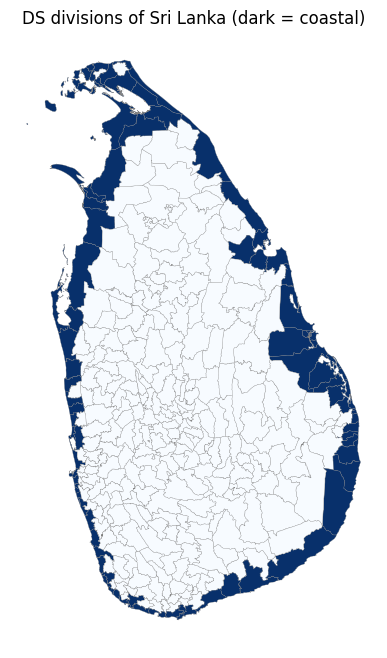

In [22]:
# Quick look (screenshot this for the report)
ax = ds.plot(column='is_coastal', cmap='Blues', edgecolor='grey', linewidth=0.2, figsize=(6, 8))
ax.set_title('DS divisions of Sri Lanka (dark = coastal)'); ax.set_axis_off()